In [1]:
!pip install torch torchvision opencv-python-headless matplotlib

In [2]:
import os, urllib.request
import numpy as np
import cv2
import torch
import torchvision
from torchvision import transforms, datasets
from torch.utils.data import DataLoader
from PIL import Image, ImageDraw
import matplotlib.pyplot as plt

torch.manual_seed(0); np.random.seed(0)
device = "cuda" if torch.cuda.is_available() else "cpu"
print("PyTorch:", torch.__version__, "| OpenCV:", cv2.__version__, "| urządzenie:", device)

PyTorch: 2.11.0+cpu | OpenCV: 4.14.0 | urządzenie: cpu


In [3]:
!unzip dane.zip

Archive:  dane.zip
   creating: dane/
   creating: dane/cat/
  inflating: dane/cat/Abyssinian_127_jpg.rf.b2553880d73a78e26e396fe7775f31be.jpg  
  inflating: dane/cat/Abyssinian_131_jpg.rf.3aeee0801499f335e3a59b51189e1351.jpg  
  inflating: dane/cat/Abyssinian_149_jpg.rf.b6b4a72a93f8bc2b239b18c5d181190c.jpg  
  inflating: dane/cat/Abyssinian_15_jpg.rf.7bc44eeb9865e35cb1d5f9ef4f53b381.jpg  
  inflating: dane/cat/Abyssinian_167_jpg.rf.1d367cb1cf82c1e5ebda79fda928cee5.jpg  
  inflating: dane/cat/Bengal_103_jpg.rf.bb684501a53abf381a6bf07f9cd2243c.jpg  
  inflating: dane/cat/Bengal_109_jpg.rf.aed42b8605ef92b579992d02e2e2cc4c.jpg  
  inflating: dane/cat/Bengal_116_jpg.rf.8c6280ad977c6c749da4d35156e49286.jpg  
  inflating: dane/cat/Bengal_13_jpg.rf.7c75131d257406a75d8d676dd9b5f5f7.jpg  
  inflating: dane/cat/Bengal_145_jpg.rf.3dadbfbb39437890fc249f7edb37cb2f.jpg  
  inflating: dane/cat/Bengal_150_jpg.rf.05c93a40014062c5ae66bae50a857aca.jpg  
  inflating: dane/cat/Bengal_165_jpg.rf.31185846cf58

Zbiór obrazów "Cats and Dogs" wykorzystany w zadaniu pochodzi z platformy Kaggle.

In [4]:
ROOT = "dane"

In [5]:
eval_tf = transforms.Compose([
    transforms.Resize((64, 64)),
    transforms.ToTensor(),
    transforms.Normalize([0.5]*3, [0.5]*3),
])
train_tf = transforms.Compose([
    transforms.Resize((64, 64)),
    transforms.RandomHorizontalFlip(),
    transforms.RandomRotation(15),
    transforms.ColorJitter(brightness=0.2, contrast=0.2),
    transforms.ToTensor(),
    transforms.Normalize([0.5]*3, [0.5]*3),
])

In [6]:
from torch.utils.data import Subset
g = torch.Generator().manual_seed(42)
n = len(datasets.ImageFolder(ROOT))
perm = torch.randperm(n, generator=g).tolist()
n_val = int(0.2 * n)
val_idx, train_idx = perm[:n_val], perm[n_val:]
train_ds = Subset(datasets.ImageFolder(ROOT, transform=train_tf), train_idx)
val_ds   = Subset(datasets.ImageFolder(ROOT, transform=eval_tf),  val_idx)
train_dl = DataLoader(train_ds, batch_size=16, shuffle=True)
val_dl   = DataLoader(val_ds,   batch_size=32, shuffle=False)

Paczka: (16, 3, 64, 64) | typ: torch.float32 | min: -1.0 | max: 1.0 | etykiety: [1, 0, 1, 0, 0, 1, 0, 1]


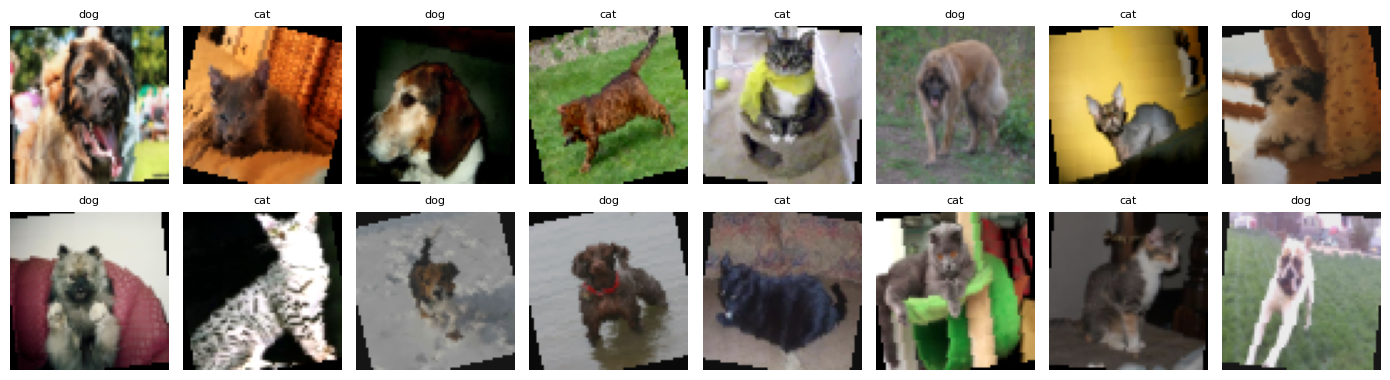

In [7]:
xb, yb = next(iter(train_dl))
print("Paczka:", tuple(xb.shape), "| typ:", xb.dtype, "| min:", xb.min().item(), "| max:", xb.max().item(), "| etykiety:", yb[:8].tolist())
fig, axes = plt.subplots(2, 8, figsize=(14, 4))
for ax, img, lb in zip(axes.flat, xb, yb):
    ax.imshow((img*0.5 + 0.5).permute(1, 2, 0).numpy())
    ax.set_title(train_ds.dataset.classes[lb], fontsize=8); ax.axis("off")
plt.tight_layout(); plt.show()

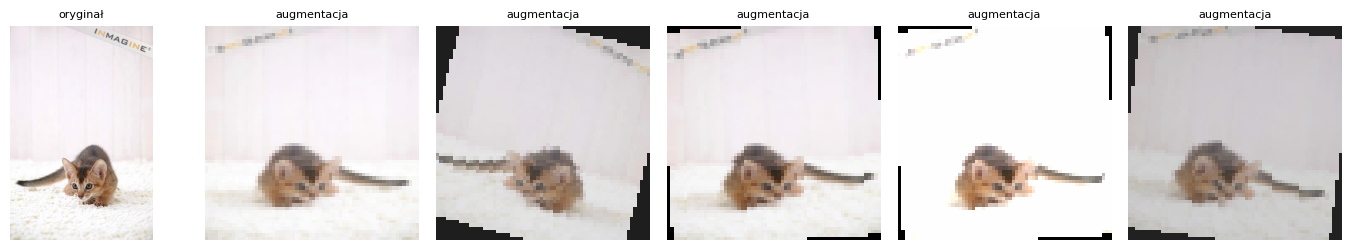

In [8]:
raw = Image.open(train_ds.dataset.samples[0][0]).convert("RGB")
fig, axes = plt.subplots(1, 6, figsize=(14, 2.6))
axes[0].imshow(raw); axes[0].set_title("oryginał", fontsize=8); axes[0].axis("off")
for ax in axes[1:]:
    aug = train_tf(raw)
    ax.imshow((aug*0.5 + 0.5).permute(1, 2, 0).numpy())
    ax.set_title("augmentacja", fontsize=8); ax.axis("off")
plt.tight_layout(); plt.show()

In [9]:
train_targets = [train_ds.dataset.targets[i] for i in train_ds.indices]
val_targets = [val_ds.dataset.targets[i] for i in val_ds.indices]

print("STATYSTYKI ZBIORU:")
print(f"Liczba klas: {len(train_ds.dataset.classes)}")
print(f"Mapowanie class_to_idx: {train_ds.dataset.class_to_idx}")
print(f"Rozmiar tensora: {list(xb[0].shape)}\n")

print(f"{'Klasa':<12} | {'Trening':<8} | {'Walidacja':<8}")
print("-" * 35)
for c_name, c_idx in train_ds.dataset.class_to_idx.items():
    print(f"{c_name:<12} | {train_targets.count(c_idx):<8} | {val_targets.count(c_idx):<8}")

STATYSTYKI ZBIORU:
Liczba klas: 2
Mapowanie class_to_idx: {'cat': 0, 'dog': 1}
Rozmiar tensora: [3, 64, 64]

Klasa        | Trening  | Walidacja
-----------------------------------
cat          | 72       | 23      
dog          | 80       | 15      
